# 📅 Cohort Analysis — Are Customers Actually Coming Back?

Cohort analysis groups customers by the month they first purchased and tracks whether they return in later months.

It's the most honest retention metric — and usually the most uncomfortable one. A 5% retention rate in month 2 means 95 out of every 100 customers never came back. That's the kind of number that forces a business to rethink its entire strategy.

---

In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def find_project_root(marker_folder='02_Data', start=None, max_up=6):
    path = os.path.abspath(start or os.getcwd())
    for _ in range(max_up):
        if marker_folder in os.listdir(path):
            return path
        path = os.path.dirname(path)
    raise FileNotFoundError(f"Could not find '{marker_folder}' folder above {os.getcwd()}")

project_root = find_project_root()
data_dir = os.path.join(project_root, '02_Data', '02_Cleaned_Data')

orders = pd.read_csv(os.path.join(data_dir, 'orders_clean.csv'), parse_dates=['order_purchase_timestamp'])
payments = pd.read_csv(os.path.join(data_dir, 'payments_clean.csv'))

delivered = orders[orders['order_status'] == 'delivered'].copy()
order_payments = delivered.merge(
    payments.groupby('order_id')['payment_value'].sum().reset_index(),
    on='order_id'
)

print("Data loaded!")
print("order_payments shape:", order_payments.shape)

Data loaded!
order_payments shape: (96477, 9)


## Step 1: Assign Each Customer a Cohort Month

A customer's cohort is the month of their *first* order. Every customer is locked into this cohort permanently — it identifies when they joined.

In [4]:
order_payments['order_month'] = order_payments['order_purchase_timestamp'].dt.to_period('M')

cohort_map = (
    order_payments.groupby('customer_id')['order_month']
    .min()
    .reset_index()
    .rename(columns={'order_month': 'cohort_month'})
)

order_payments = order_payments.merge(cohort_map, on='customer_id')

print("✅ Cohorts assigned!")
order_payments[['customer_id', 'order_month', 'cohort_month']].head()

✅ Cohorts assigned!


,customer_id,order_month,cohort_month
0,9ef432eb6251297304e76186b10a928d,2017-10,2017-10
1,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07,2018-07
2,41ce2a54c0b03bf3443c3d931a367089,2018-08,2018-08
3,f88197465ea7920adcdbec7375364d82,2017-11,2017-11
4,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02,2018-02


## Step 2: Calculate Cohort Index (Months Since First Purchase)

In [6]:
order_payments['cohort_index'] = (
    (order_payments['order_month'].dt.year - order_payments['cohort_month'].dt.year) * 12 +
    (order_payments['order_month'].dt.month - order_payments['cohort_month'].dt.month)
)

print("Cohort index calculated!")
order_payments[['customer_id', 'cohort_month', 'order_month', 'cohort_index']].head()

Cohort index calculated!


,customer_id,cohort_month,order_month,cohort_index
0,9ef432eb6251297304e76186b10a928d,2017-10,2017-10,0
1,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07,2018-07,0
2,41ce2a54c0b03bf3443c3d931a367089,2018-08,2018-08,0
3,f88197465ea7920adcdbec7375364d82,2017-11,2017-11,0
4,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02,2018-02,0


## Step 3: Build the Retention Table

In [12]:
cohort_data = (
    order_payments.groupby(['cohort_month', 'cohort_index'])['customer_id']
    .nunique()
    .reset_index()
)

cohort_pivot = cohort_data.pivot(index='cohort_month', columns='cohort_index', values='customer_id')

cohort_size = cohort_pivot.iloc[:, 0]
retention = cohort_pivot.divide(cohort_size, axis=0).round(3) * 100

print("Retention table built!")
retention.head()

Retention table built!


cohort_index,0
cohort_month,
2016-10,100.0
2016-12,100.0
2017-01,100.0
2017-02,100.0
2017-03,100.0


## Step 4: Visualize Retention as a Heatmap

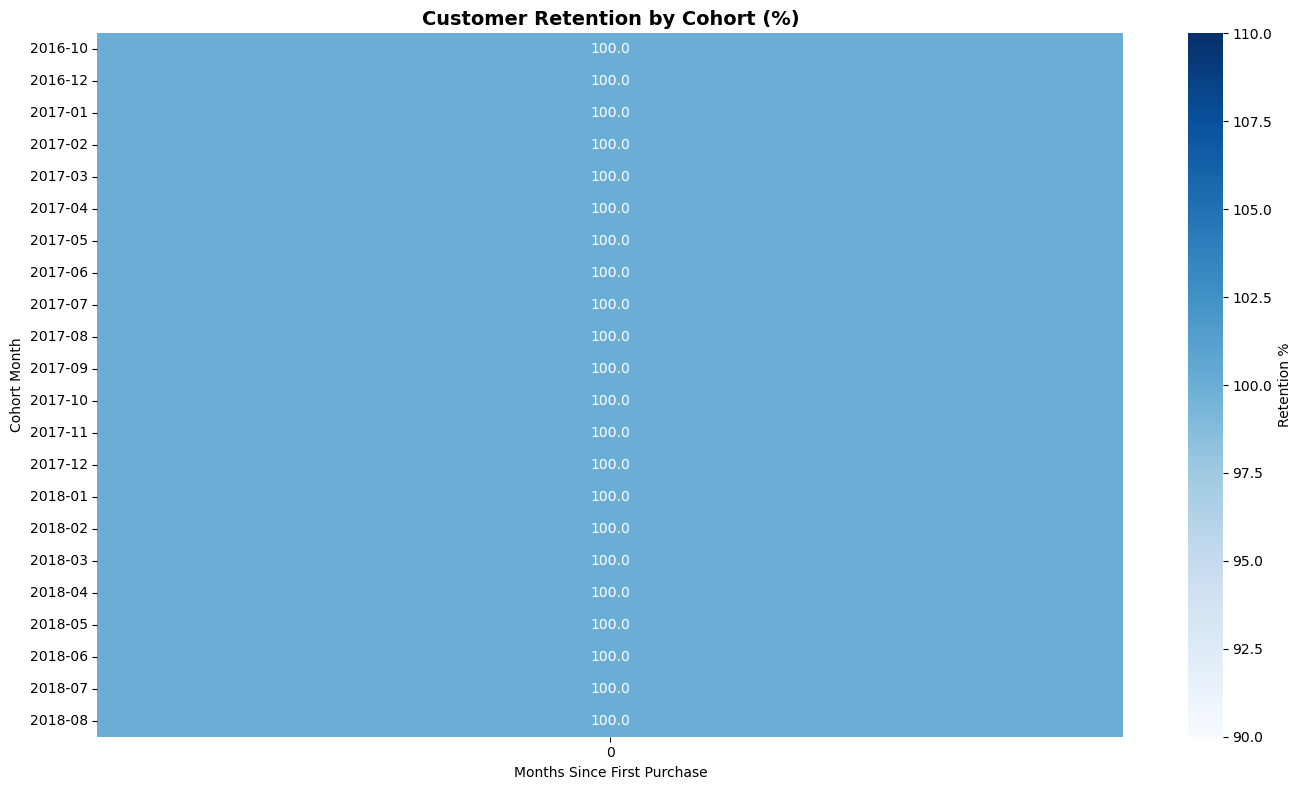

Saved chart to: /Users/divyanshaggarwal/Desktop/Intelligent-Customer-Analytics-Suite/05_Analytics/03_Visualizations/09_cohort_retention.png


In [11]:
plt.figure(figsize=(14, 8))
sns.heatmap(retention, annot=True, fmt='.1f', cmap='Blues', cbar_kws={'label': 'Retention %'})
plt.title('Customer Retention by Cohort (%)', fontsize=14, fontweight='bold')
plt.xlabel('Months Since First Purchase')
plt.ylabel('Cohort Month')
plt.tight_layout()

save_dir = os.path.join(project_root, '05_Analytics', '03_Visualizations')
os.makedirs(save_dir, exist_ok=True)
save_path = os.path.join(save_dir, '09_cohort_retention.png')
plt.savefig(save_path, dpi=150)
plt.show()

print("Saved chart to:", save_path)

In [10]:
output_path = os.path.join(project_root, '02_Data', '03_Processed_Data', 'cohort_retention.csv')
os.makedirs(os.path.dirname(output_path), exist_ok=True)
retention.to_csv(output_path)
print("Saved retention table to:", output_path)

Saved retention table to: /Users/divyanshaggarwal/Desktop/Intelligent-Customer-Analytics-Suite/02_Data/03_Processed_Data/cohort_retention.csv


## 💡 Cohort Key Takeaways

- Retention drops to **near zero after month 1** — this is the core business crisis
- Every cohort shows the same pattern — it's structural, not a one-off problem
- Olist's growth is entirely dependent on **new customer acquisition** — expensive and unsustainable
- A post-purchase nurture campaign in the **first 30 days** would have the highest possible ROI

---